# E-commerce Sales Performance Analysis

Analyze e-commerce sales performance to understand revenue trends, product performance, and purchasing behavior.

**Business Objective**: Identify sales patterns, top-performing products, and customer purchasing trends to support business and marketing decisions.

## 1. Import Libraries

In [1]:
import os

import pandas as pd
import matplotlib.pyplot as plt

## 2. Load Dataset

The data is the UCI Online Retail dataset (a UK online retailer, December 2010 – December 2011), saved as a UTF-8 CSV file. See `data/README.md` for where to download it.

In [2]:
# Data file location: ../data in the GitHub layout (notebook/ folder), the project folder locally
data_dir = "../data" if os.path.basename(os.getcwd()) == "notebook" else "."

# The file is UTF-8 with a byte-order mark, so "utf-8-sig" keeps the first column name clean
df = pd.read_csv(os.path.join(data_dir, "online_retail.csv"), encoding="utf-8-sig")
print(f"{len(df):,} rows, {df.shape[1]} columns")

541,909 rows, 8 columns


## 3. Data Cleaning

1. Remove **non-product lines**: postage, carriage, manual adjustments, fees, samples, and gift vouchers.
2. Remove **order lines cancelled in full within 24 hours** (same customer, product, and quantity). These are order-entry mistakes, not real sales: for example, an order for 80,995 paper craft sets was cancelled 12 minutes later.
3. Remove rows without a customer ID or product description, plus returns and cancellations (`Quantity <= 0`) and invalid prices (`UnitPrice <= 0`).

In [3]:
# Dates look like "12/1/10 8:26" (month/day/two-digit year), so the format is set explicitly
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], format="%m/%d/%y %H:%M")

# 1) Non-product lines: postage, carriage, manual adjustments, fees, samples, gift vouchers
NON_PRODUCT_CODES = ["POST", "DOT", "C2", "M", "m", "D", "S", "B", "CRUK", "BANK CHARGES", "AMAZONFEE"]
codes = df["StockCode"].astype(str)
is_non_product = codes.isin(NON_PRODUCT_CODES) | codes.str.startswith("gift_")
print(f"Non-product lines removed: {is_non_product.sum():,}")
df = df[~is_non_product]

Non-product lines removed: 2,946


In [4]:
# 2) Order lines cancelled in full within 24 hours (same customer, product, and quantity).
#    These are order-entry mistakes, not real sales.
def remove_same_day_cancellations(df, invoice, customer, product, qty, date, price):
    is_cancel = df[invoice].astype(str).str.startswith("C")
    purchases = df[~is_cancel].dropna(subset=[customer]).reset_index()
    cancels = df[is_cancel].dropna(subset=[customer]).reset_index()
    cancels[qty] = -cancels[qty]
    pairs = purchases.merge(cancels, on=[customer, product, qty], suffixes=("", "_cancel"))
    pairs["gap"] = pairs[date + "_cancel"] - pairs[date]
    pairs = pairs[(pairs["gap"] >= pd.Timedelta(0)) & (pairs["gap"] <= pd.Timedelta(hours=24))]
    # Match each cancellation to its nearest earlier purchase, one to one
    pairs = pairs.sort_values("gap").drop_duplicates("index_cancel").drop_duplicates("index")
    pairs["value"] = pairs[qty] * pairs[price]
    pairs["minutes_to_cancel"] = (pairs["gap"].dt.total_seconds() // 60).astype(int)
    return df.drop(index=pairs["index"]), pairs


df, cancelled = remove_same_day_cancellations(
    df, invoice="InvoiceNo", customer="CustomerID", product="StockCode",
    qty="Quantity", date="InvoiceDate", price="UnitPrice"
)
print(f"Order lines cancelled within 24 hours removed: {len(cancelled):,} (worth £{cancelled['value'].sum():,.0f})")
print(cancelled.nlargest(3, "value")[["InvoiceNo", "Description", "Quantity", "value", "minutes_to_cancel"]].to_string(index=False))

Order lines cancelled within 24 hours removed: 640 (worth £330,320)
InvoiceNo                    Description  Quantity    value  minutes_to_cancel
   581483    PAPER CRAFT , LITTLE BIRDIE     80995 168469.6                 12
   541431 MEDIUM CERAMIC TOP STORAGE JAR     74215  77183.6                 16
   556444 PICNIC BASKET WICKER 60 PIECES        60  38970.0                 11


In [5]:
df = df.dropna(subset=["CustomerID", "Description"])
df = df[df["Quantity"] > 0]
df = df[df["UnitPrice"] > 0]
print(f"{len(df):,} rows after cleaning")

395,700 rows after cleaning


## 4. Feature Engineering

Create a `Sales` column (`Quantity × UnitPrice`).

In [6]:
df["Sales"] = df["Quantity"] * df["UnitPrice"]

## 5. Monthly Sales Trend

In [7]:
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M").astype(str)
monthly_sales = df.groupby("YearMonth", as_index=False)["Sales"].sum()

print(monthly_sales)

   YearMonth        Sales
0    2010-12   563962.460
1    2011-01   484496.980
2    2011-02   443136.650
3    2011-03   581854.420
4    2011-04   453560.781
5    2011-05   660295.220
6    2011-06   613664.090
7    2011-07   591267.411
8    2011-08   632260.120
9    2011-09   936357.591
10   2011-10   993321.180
11   2011-11  1132346.720
12   2011-12   344222.770


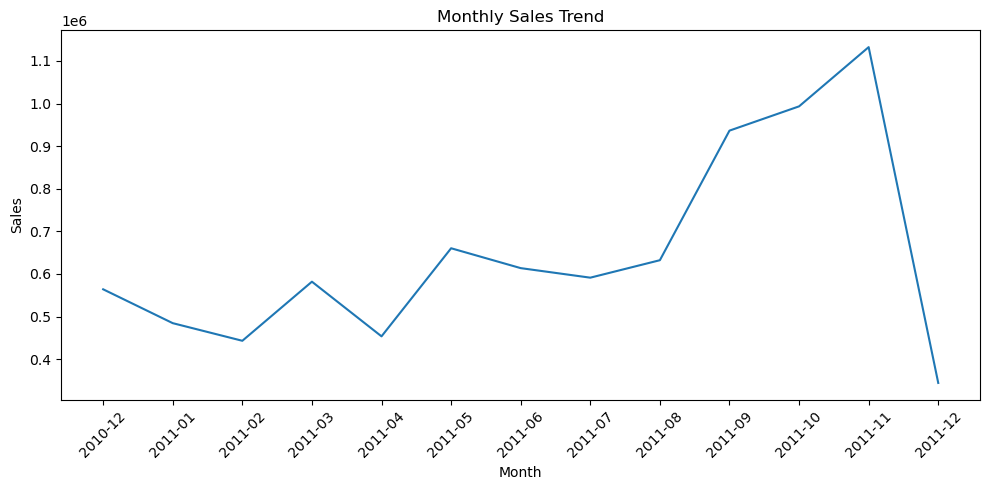

In [8]:
plt.figure(figsize=(10, 5))
plt.plot(monthly_sales["YearMonth"], monthly_sales["Sales"])
plt.xticks(rotation=45)
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.tight_layout()
plt.show()

## 6. Top 10 Products by Sales

In [9]:
top_products = (
    df.groupby("Description", as_index=False)["Sales"]
    .sum()
    .sort_values("Sales", ascending=False)
    .head(10)
)

print(top_products)

                             Description      Sales
2759            REGENCY CAKESTAND 3 TIER  141257.95
3690  WHITE HANGING HEART T-LIGHT HOLDER   99137.75
1757             JUMBO BAG RED RETROSPOT   83923.10
2338                       PARTY BUNTING   68824.53
216        ASSORTED COLOUR BIRD ORNAMENT   56558.37
2648                  RABBIT NIGHT LIGHT   51333.72
718                        CHILLI LIGHTS   45957.51
2307     PAPER CHAIN KIT 50'S CHRISTMAS    41926.18
374             BLACK RECORD COVER FRAME   39049.55
1755             JUMBO BAG PINK POLKADOT   36544.59


## 7. Sales by Country (Top 10)

In [10]:
country_sales = (
    df.groupby("Country", as_index=False)["Sales"]
    .sum()
    .sort_values("Sales", ascending=False)
    .head(10)
)

print(country_sales)

           Country        Sales
35  United Kingdom  6941712.733
23     Netherlands   283889.340
10            EIRE   252763.060
14         Germany   205557.990
13          France   183186.220
0        Australia   137869.710
30           Spain    55725.110
32     Switzerland    52258.000
19           Japan    37416.370
3          Belgium    36927.340


## 8. Key Insights & Business Recommendations

**Key insights**
- Total revenue after cleaning is about **£8.43M**. Sales climb from September and peak in **November 2011 (£1.13M)**, about 2.3 times the February–April average, so demand is strongly seasonal. December 2011 looks low only because the data ends on December 9.
- The **United Kingdom** brings in about **82%** of revenue (£6.94M). The Netherlands, EIRE, Germany, and France are the largest secondary markets.
- The top sellers are **REGENCY CAKESTAND 3 TIER** (£141K), **WHITE HANGING HEART T-LIGHT HOLDER** (£99K), and **JUMBO BAG RED RETROSPOT** (£84K).
- Cleaning changes the product ranking. Before removing non-product lines and same-day cancellations, POSTAGE and Manual were in the top 10, and one cancelled order of 80,995 units made PAPER CRAFT, LITTLE BIRDIE look like the #1 product.

**Business recommendations**
- Plan inventory and marketing for the September–November peak.
- Protect the UK customer base, and test growth in the largest secondary markets.
- Keep the top sellers in stock ahead of the fall peak.

## 9. Export CSVs for Tableau Dashboard

The CSV files below feed the interactive Tableau dashboard and are saved in the project's `outputs/` folder.

Recommended dashboard sections:

- KPI Cards (Revenue, Orders, Customers)
- Monthly Sales Trend
- Top Products by Sales
- Country Sales Performance

Files generated:
- `cleaned_ecommerce_data.csv` (row-level data; a zipped copy is kept on GitHub)
- `monthly_sales.csv`
- `top_products.csv`
- `country_sales.csv`

In [11]:
# Save CSVs in the project's outputs folder:
# "../outputs" when the notebook sits in a notebook/ folder (GitHub layout),
# "outputs" when it sits in the project folder itself (local layout)
output_dir = "../outputs" if os.path.basename(os.getcwd()) == "notebook" else "outputs"
os.makedirs(output_dir, exist_ok=True)

# Row-level cleaned dataset (Tableau source), plus a zipped copy small enough for GitHub
df.to_csv(os.path.join(output_dir, "cleaned_ecommerce_data.csv"), index=False)
df.to_csv(
    os.path.join(output_dir, "cleaned_ecommerce_data.csv.zip"), index=False,
    compression={"method": "zip", "archive_name": "cleaned_ecommerce_data.csv"}
)

# Aggregated tables for Tableau
monthly_sales.to_csv(os.path.join(output_dir, "monthly_sales.csv"), index=False)
top_products.to_csv(os.path.join(output_dir, "top_products.csv"), index=False)
country_sales.to_csv(os.path.join(output_dir, "country_sales.csv"), index=False)

print(f"Saved to {output_dir}/:")
print("  cleaned_ecommerce_data.csv (+ .zip)")
print("  monthly_sales.csv")
print("  top_products.csv")
print("  country_sales.csv")

Saved to ../outputs/:
  cleaned_ecommerce_data.csv (+ .zip)
  monthly_sales.csv
  top_products.csv
  country_sales.csv
